# Exploratory Data Analysis – Indian IPO Listing-Day Gains

**Course:** Introduction to Machine Learning (PCCAIML502)  
**Dataset:** `ipo_listing_gain_clean.csv` (1,060 listed Mainboard & SME IPOs)

This notebook explores Day-1 listing gain distributions, segment differences (Mainboard vs. SME, Book-Built vs. Fixed-Price), sector performance, subscription & GMP relationships, macro market regimes, and missingness patterns – and exports summary statistics (`artifacts/eda_stats.json`) for reporting and the interactive frontend.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
os.makedirs("artifacts/plots", exist_ok=True)

# Preserve string dtype on bse_code so leading zeros are never coerced
df = pd.read_csv("ipo_listing_gain_clean.csv", dtype={"bse_code": str})
df["listing_date"] = pd.to_datetime(df["listing_date"])
df["listing_year"] = df["listing_date"].dt.year
df["segment"] = np.where(df["is_sme"] == 1, "SME", "Mainboard")

print(f"Shape: {df.shape}")
print(f"Date span: {df['listing_date'].min().date()} to {df['listing_date'].max().date()}")
print(df["segment"].value_counts())

Shape: (1060, 68)
Date span: 2023-11-06 to 2026-11-11
segment
SME          736
Mainboard    324
Name: count, dtype: int64


---
## 1. Listing-Day Target Distributions (Mainboard vs. SME)

Overall Target Summary (%):
       target_open_gain_pct  target_typical_gain_pct  target_close_gain_pct
count               1060.00                  1060.00                1060.00
mean                  21.98                    23.02                  23.60
std                   34.51                    36.37                  37.42
min                  -39.63                   -37.88                 -36.61
25%                    0.00                    -1.49                  -1.50
50%                    8.85                     9.70                  10.30
75%                   37.00                    37.60                  40.00
max                  181.46                   189.24                 195.53

By Market Segment (target_typical_gain_pct):
           count   mean  median    std  pct_positive  pct_gt_20
segment                                                        
Mainboard    324  18.56    9.90  30.40         72.53      34.88
SME          736  24.98    9.34  38.57         70.

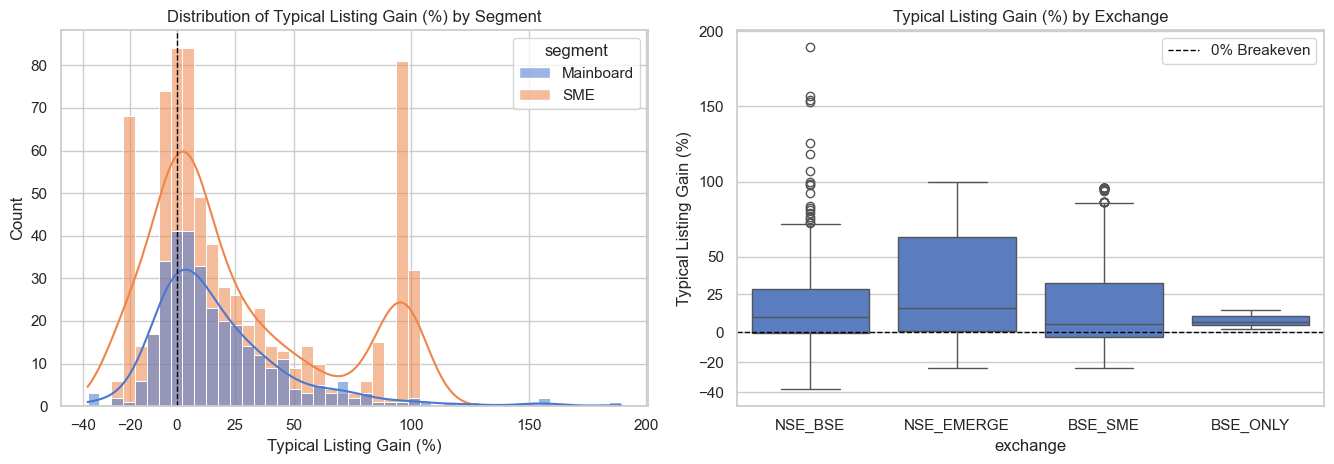

In [2]:
targets = ["target_open_gain_pct", "target_typical_gain_pct", "target_close_gain_pct"]
print("Overall Target Summary (%):")
print(df[targets].describe().round(2))

print("\nBy Market Segment (target_typical_gain_pct):")
seg_stats = df.groupby("segment")["target_typical_gain_pct"].agg([
    "count", "mean", "median", "std",
    ("pct_positive", lambda s: (s > 0).mean() * 100),
    ("pct_gt_20", lambda s: (s > 20).mean() * 100),
]).round(2)
print(seg_stats)

gain_ticks = [-40, -20, 0, 25, 50, 100, 150, 200]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
sns.histplot(data=df, x="target_typical_gain_pct", hue="segment", bins=45, kde=True, ax=axes[0], alpha=0.55)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1, label="0% Breakeven")
axes[0].set_xticks(gain_ticks)
axes[0].set_title("Distribution of Typical Listing Gain (%) by Segment")
axes[0].set_xlabel("Typical Listing Gain (%)")

sns.boxplot(data=df, x="exchange", y="target_typical_gain_pct", ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="0% Breakeven")
axes[1].set_yticks(gain_ticks)
axes[1].set_title("Typical Listing Gain (%) by Exchange")
axes[1].set_ylabel("Typical Listing Gain (%)")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig("artifacts/plots/eda_target_distribution.png", dpi=300)
plt.show()

---
## 2. Subscription Demand, GMP & Correlation Analysis

Top Pearson Correlations with target_typical_gain_pct:
gmp_close_day_pct          0.795
sub_total_x                0.661
sub_nii_total_x            0.640
sub_rii_x                  0.629
sub_qib_total_x            0.613
smallcap250_ret_22d_pct    0.235
nifty50_ret_22d_pct        0.172
india_vix_close            0.080
roe_pct                    0.066
roce_pct                   0.056
tier1_anchor_share_pct    -0.026
ofs_pct                   -0.050
post_issue_mcap_cr        -0.072
pe_post_ipo               -0.079
total_issue_size_cr       -0.083
gmp_momentum_pct          -0.117
Name: target_typical_gain_pct, dtype: float64

Listing Gain by Total Subscription Bucket:
            count   mean  median  pct_positive
sub_bucket                                    
< 2x          173  -1.09   -3.00         37.57
2x–10x        226   1.16    0.48         50.88
10x–50x       184  10.83    6.68         71.74
50x–150x      230  28.57   20.53         89.57
> 150x        247  63.80   71.03         95.9

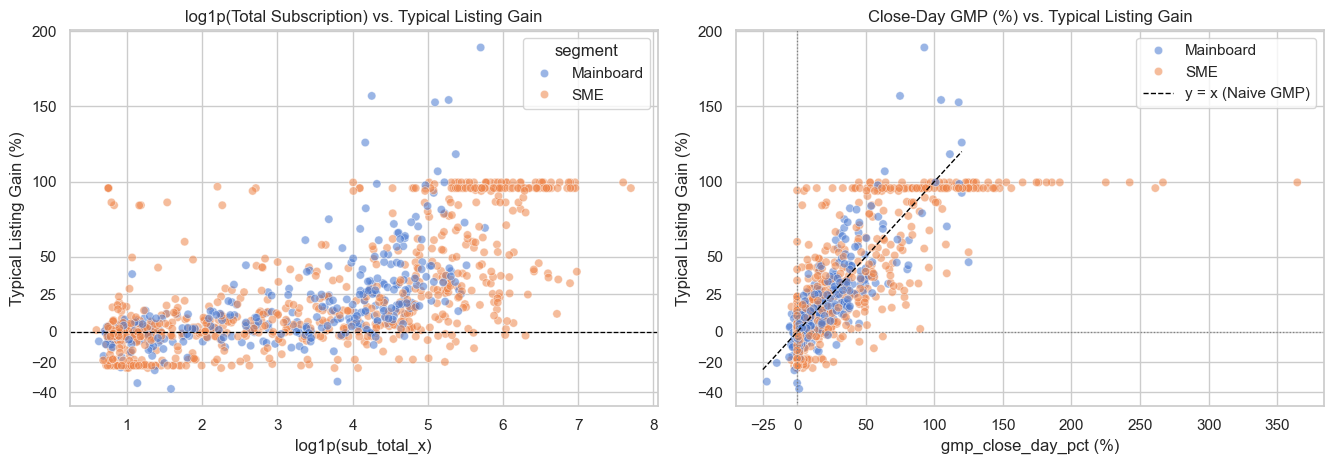

In [3]:
num_check = [
    "target_typical_gain_pct", "gmp_close_day_pct", "gmp_momentum_pct",
    "sub_total_x", "sub_nii_total_x", "sub_rii_x", "sub_qib_total_x",
    "total_issue_size_cr", "post_issue_mcap_cr", "tier1_anchor_share_pct",
    "ofs_pct", "pe_post_ipo", "roe_pct", "roce_pct",
    "nifty50_ret_22d_pct", "smallcap250_ret_22d_pct", "india_vix_close"
]
corr_series = df[num_check].corr()["target_typical_gain_pct"].drop("target_typical_gain_pct").sort_values(ascending=False)
print("Top Pearson Correlations with target_typical_gain_pct:")
print(corr_series.round(3))

# Invert log1p to interpret human-readable subscription multiple buckets
raw_sub = np.expm1(df["sub_total_x"])
df["sub_bucket"] = pd.cut(
    raw_sub,
    bins=[0, 2, 10, 50, 150, np.inf],
    labels=["< 2x", "2x–10x", "10x–50x", "50x–150x", "> 150x"],
)
sub_bucket_stats = df.groupby("sub_bucket", observed=False)["target_typical_gain_pct"].agg(["count", "mean", "median", ("pct_positive", lambda s: (s > 0).mean() * 100)]).round(2)
print("\nListing Gain by Total Subscription Bucket:")
print(sub_bucket_stats)

gain_ticks = [-40, -20, 0, 25, 50, 100, 150, 200]
gmp_xticks = [-25, 0, 50, 100, 150, 200, 250, 300, 350]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
sns.scatterplot(data=df, x="sub_total_x", y="target_typical_gain_pct", hue="segment", alpha=0.55, ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.9, label="0% Breakeven")
axes[0].set_yticks(gain_ticks)
axes[0].set_title("log1p(Total Subscription) vs. Typical Listing Gain")
axes[0].set_xlabel("log1p(sub_total_x)")
axes[0].set_ylabel("Typical Listing Gain (%)")

sns.scatterplot(data=df, x="gmp_close_day_pct", y="target_typical_gain_pct", hue="segment", alpha=0.55, ax=axes[1])
axes[1].plot([-25, 120], [-25, 120], color="black", linestyle="--", linewidth=1, label="y = x (Naive GMP)")
axes[1].axhline(0, color="gray", linestyle=":", linewidth=0.9)
axes[1].axvline(0, color="gray", linestyle=":", linewidth=0.9)
axes[1].set_xticks(gmp_xticks)
axes[1].set_yticks(gain_ticks)
axes[1].set_title("Close-Day GMP (%) vs. Typical Listing Gain")
axes[1].set_xlabel("gmp_close_day_pct (%)")
axes[1].set_ylabel("Typical Listing Gain (%)")
axes[1].legend()
plt.tight_layout()
plt.savefig("artifacts/plots/eda_sub_and_gmp.png", dpi=300)
plt.show()

---
## 3. Macro Sector Performance, Yearly Trends & Structural Signals

Sector-wise Typical Listing Gain (%):
                               count   mean  median  pct_positive
sector                                                           
Industrials & Capital Goods      263  32.88   18.55         76.43
IT & Tech                         84  31.50   17.50         78.57
Energy & Utilities                16  24.50   16.40         75.00
Chemicals & Petrochemicals        45  25.08   13.50         75.56
Healthcare & Pharma               69  21.49   11.69         73.91
Infrastructure & Construction     78  22.80   10.07         78.21
Financials                        48  18.67    9.82         72.92
Agriculture                       27  26.38    8.44         59.26
Consumer Goods & Retail          212  15.54    6.06         65.09
Media & Entertainment             25  20.97    5.37         64.00
Real Estate                       12  11.07    5.27         66.67
Auto & Ancillaries                41  14.99    5.22         70.73
Other/Diversified                 94  

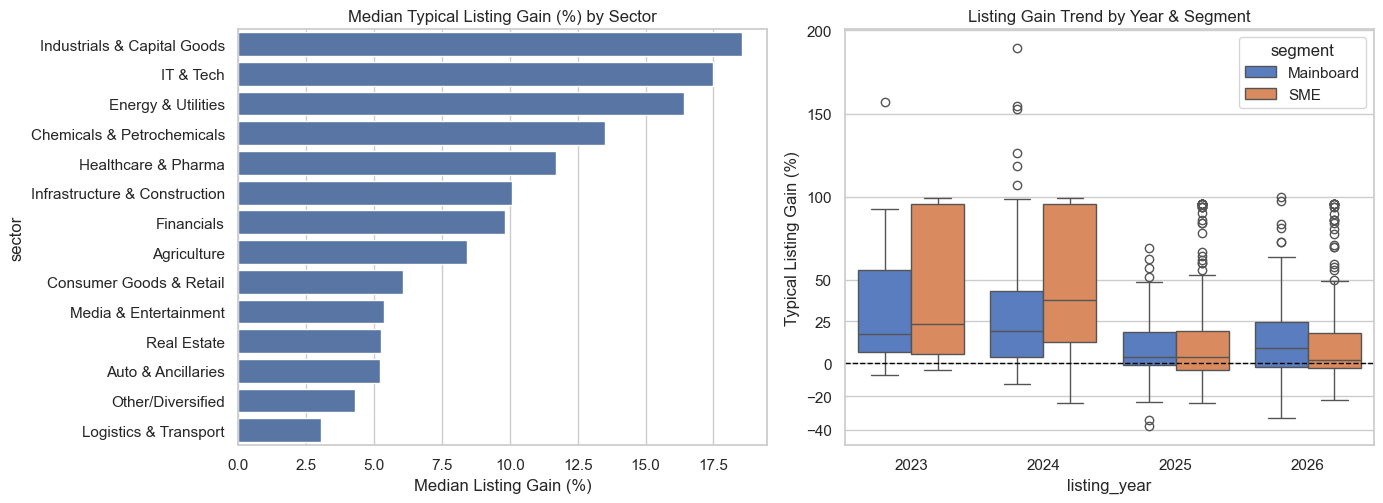

In [4]:
sector_stats = (
    df.groupby("sector")["target_typical_gain_pct"]
    .agg(["count", "mean", "median", ("pct_positive", lambda s: (s > 0).mean() * 100)])
    .sort_values("median", ascending=False)
    .round(2)
)
print("Sector-wise Typical Listing Gain (%):")
print(sector_stats)

year_stats = (
    df.groupby("listing_year")["target_typical_gain_pct"]
    .agg(["count", "mean", "median", ("pct_positive", lambda s: (s > 0).mean() * 100)])
    .round(2)
)
print("\nYear-wise Typical Listing Gain (%):")
print(year_stats)

gain_ticks = [-40, -20, 0, 25, 50, 100, 150, 200]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sector_order = sector_stats.index.tolist()
sns.barplot(data=df, y="sector", x="target_typical_gain_pct", order=sector_order, estimator=np.median, errorbar=None, ax=axes[0], color="#4c72b0")
axes[0].set_title("Median Typical Listing Gain (%) by Sector")
axes[0].set_xlabel("Median Listing Gain (%)")

sns.boxplot(data=df, x="listing_year", y="target_typical_gain_pct", hue="segment", ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="0% Breakeven")
axes[1].set_yticks(gain_ticks)
axes[1].set_title("Listing Gain Trend by Year & Segment")
axes[1].set_ylabel("Typical Listing Gain (%)")
plt.tight_layout()
plt.savefig("artifacts/plots/eda_sectors_and_years.png", dpi=300)
plt.show()

---
## 4. Temporal Missingness Check & Export EDA Summary JSON for UI

In [5]:
# 2023-2024 have 92-100% NaNs in app_*; excluding app_* prevents trees from using missingness as a year proxy
app_cols = ["app_nii_x", "app_rii_x", "app_qib_fii", "app_qib_dfi", "app_qib_mf", "app_qib_other"]
print("app_* Missingness Rate by Year (reason for exclusion from X):")
print(df.groupby("listing_year")[app_cols].apply(lambda g: g.isna().mean()).round(3))

eda_summary = {
    "total_ipos": int(len(df)),
    "mainboard_count": int((df["is_sme"] == 0).sum()),
    "sme_count": int((df["is_sme"] == 1).sum()),
    "overall_typical_mean_pct": round(float(df["target_typical_gain_pct"].mean()), 2),
    "overall_typical_median_pct": round(float(df["target_typical_gain_pct"].median()), 2),
    "overall_positive_rate_pct": round(float((df["target_typical_gain_pct"] > 0).mean() * 100), 2),
    "segment_stats": seg_stats.reset_index().to_dict(orient="records"),
    "subscription_buckets": sub_bucket_stats.reset_index().to_dict(orient="records"),
    "sector_stats": sector_stats.reset_index().to_dict(orient="records"),
    "yearly_stats": year_stats.reset_index().to_dict(orient="records"),
    "top_correlations": [
        {"feature": k, "corr": round(float(v), 3)} for k, v in corr_series.items()
    ],
    "issue_type_stats": df.groupby("issue_type")["target_typical_gain_pct"].agg(["count", "mean", "median"]).round(2).reset_index().to_dict(orient="records"),
    "upper_band_stats": df.groupby("priced_at_upper_band")["target_typical_gain_pct"].agg(["count", "mean", "median"]).round(2).reset_index().to_dict(orient="records"),
}

with open("artifacts/eda_stats.json", "w", encoding="utf-8") as f:
    json.dump(eda_summary, f, indent=2)
print("Saved EDA stats to artifacts/eda_stats.json")

app_* Missingness Rate by Year (reason for exclusion from X):
              app_nii_x  app_rii_x  app_qib_fii  app_qib_dfi  app_qib_mf  \
listing_year                                                               
2023              1.000      1.000        1.000        1.000       1.000   
2024              1.000      1.000        0.916        0.916       0.916   
2025              0.285      0.177        0.153        0.153       0.153   
2026              0.099      0.000        0.099        0.099       0.099   

              app_qib_other  
listing_year                 
2023                  1.000  
2024                  0.916  
2025                  0.153  
2026                  0.099  
Saved EDA stats to artifacts/eda_stats.json
